# Default Settings

In [ ]:
import rby1_sdk as rby
import time
import numpy as np
from matplotlib import pyplot as plt
import inspect

np.set_printoptions(suppress=True, precision=3, linewidth=300)  

# Connect to Robot

In [8]:
### 1. Address ###
ROBOT_ADDRESS = "localhost:50051"           # For Docker Simulation
# ROBOT_ADDRESS = "192.168.30.1:50051"        # For Real Robot

### 1. Address ###
robot = rby.create_robot_a(ROBOT_ADDRESS)   # Robot Model is "A"
model = robot.model()
if not robot.connect():
    print("Could not connect to robot")
    exit(1)
else:
    print("Successfully connected to the robot!!")

Successfully connected to the robot!!


# Power ON the Robot

In [22]:
robot.power_on(".*")         # Turn on all the power (5v, 12v, 24v, 48v)

True

In [ ]:
# robot.power_off(".*")  

True

In [23]:
robot.servo_on(".*")         # Enable servo motors on all actuators

True

In [24]:
# Reset the fault control manager
robot.reset_fault_control_manager()

# Enable control manager with limited mode disabled
robot.enable_control_manager(unlimited_mode_enabled=True)

True

# Move to Zero Position

In [ ]:
minimum_time = 5    # Consumed Time
rc_builder = rby.RobotCommandBuilder().set_command(
    rby.ComponentBasedCommandBuilder().set_body_command(
        rby.BodyComponentBasedCommandBuilder()
        # Set Torso Command with Joint Position Command
        .set_torso_command(
            rby.JointPositionCommandBuilder()
            .set_minimum_time(minimum_time)
            .set_position([0.] * 6)     # Unit: rad / [Torso_0(Roll-ankle), Torso_1(Pitch-ankle), Torso_2(Pitch-knee), Torso_3(Pitch-hip), Torso_4(Roll-hip), Torso_5(Yaw)]
        )
        # Set Right Arm Command with Joint Position Command
        .set_right_arm_command(
            rby.JointPositionCommandBuilder()
            .set_minimum_time(minimum_time)
            .set_position([0.] * 7)     # Unit: rad / [right_arm_0(Pitch-shoulder), right_arm_1(Roll-shoulder), right_arm_2(Yaw-shoulder), right_arm_3(Pitch-elbow), right_arm_4(Yaw-elbow), right_arm_5(Pitch-wrist), right_arm_6(Yaw-wrist)]
        )
        # Set Left Arm Command with Joint Position Command
        .set_left_arm_command(
            rby.JointPositionCommandBuilder()
            .set_minimum_time(minimum_time)
            .set_position([0.] * 7)     # Unit: rad / [left_arm_0(Pitch-shoulder), left_arm_1(Roll-shoulder), left_arm_2(Yaw-shoulder), left_arm_3(Pitch-elbow), left_arm_4(Yaw-elbow), left_arm_5(Pitch-wrist), left_arm_6(Yaw-wrist)]
        )
    )
)
handler = robot.send_command(rc_builder)
feedback = handler.get()  # Wait for finish and get feedback from control
print(feedback.finish_code)

FinishCode.Ok


# Get Robot State

[‘right_wheel’, ‘left_wheel’, ‘torso_0’, ‘torso_1’, ‘torso_2’, ‘torso_3’, ‘torso_4’, ‘torso_5’, ‘right_arm_0’, ‘right_arm_1’, ‘right_arm_2’, ‘right_arm_3’, ‘right_arm_4’, ‘right_arm_5’, ‘right_arm_6’, ‘left_arm_0’, ‘left_arm_1’, ‘left_arm_2’, ‘left_arm_3’, ‘left_arm_4’, ‘left_arm_5’, ‘left_arm_6’, ‘head_0’, ‘head_1’]

body_idx:      [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21] \
mobility_idx:  [0, 1] \
torso_idx:     [2, 3, 4, 5, 6, 7] \
right_arm_idx: [8, 9, 10, 11, 12, 13, 14] \
left_arm_idx:  [15, 16, 17, 18, 19, 20, 21] \
head_idx:      [22, 23] 

In [28]:
robot_state = robot.get_state()

print("# Position")
print(
    f"Torso: {robot_state.position[model.torso_idx]}, Right Arm: {robot_state.position[model.right_arm_idx]}, Left Arm: {robot_state.position[model.left_arm_idx]}")
print("# Current")
print(
    f"Torso: {robot_state.current[model.torso_idx]}, Right Arm: {robot_state.current[model.right_arm_idx]}, Left Arm: {robot_state.current[model.left_arm_idx]}")

# Position
Torso: [-0.  0.  0.  0. -0.  0.], Right Arm: [-0.  0.  0. -0.  0. -0. -0.], Left Arm: [-0. -0. -0. -0. -0. -0. -0.]
# Current
Torso: [-5.997  2.581  3.905  5.024 -2.01  -0.009], Right Arm: [-0.2   -0.42  -0.001  1.32  -0.001 -0.054  0.   ], Left Arm: [-0.176  0.355  0.001  1.25   0.001 -0.03   0.   ]


In [ ]:
robot_state_properties = [name for name, obj in
                          inspect.getmembers(type(robot_state), lambda x: isinstance(x, property))]
print(f"You can get the various states from robot: {robot_state_properties}")

# Get Robot State Stream

In [ ]:
def ex3_cb_robot_state(robot_state, control_manager_state):
    with np.printoptions(suppress=True, precision=3, linewidth=300):
        print(robot_state.position)
        
        
robot.start_state_update(ex3_cb_robot_state, 10)        # (Callback function, rate=Hz) 
time.sleep(2)                                           # rate=10Hz, time=2sec -> 2/0.1 = 20
robot.stop_state_update()

[ 0.003  0.003 -0.     0.     0.     0.    -0.     0.    -0.     0.     0.    -0.     0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.     0.    -0.   ]
[ 0.003  0.003 -0.     0.     0.     0.    -0.     0.    -0.     0.     0.    -0.     0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.     0.    -0.   ]
[ 0.003  0.003 -0.     0.     0.     0.    -0.     0.    -0.     0.     0.    -0.     0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.     0.    -0.   ]
[ 0.003  0.003 -0.     0.     0.     0.    -0.     0.    -0.    -0.     0.    -0.     0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.     0.    -0.   ]
[ 0.003  0.003 -0.     0.     0.     0.    -0.     0.    -0.     0.     0.    -0.     0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.     0.    -0.   ]
[ 0.003  0.003 -0.     0.     0.     0.    -0.     0.    -0.     0.     0.    -0.     0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0.    -0

# Parameters

In [37]:
parameter_list = robot.get_parameter_list()
ptype_name = {0: 'int', 
              1: 'float', 
              2: 'str', 
              3: 'list[float] (length: 3)', 
              4: 'list[float] (length: 6)', 
              5: 'list[float] (length: 7)'}
print("# Parameters")
for [pname, ptype] in parameter_list:
    print(f"{pname}: {ptype_name[ptype]}")

# Parameters
se2_velocity_command.canceling_time: float
gravity: list[float] (length: 3)
servo_on_command.timeout: float
servo_on_command.new_data_timeout: float
power_command.timeout: float
cartesian_command.cutoff_frequency: float
hotspot.password: str
hotspot.ssid: str
major_fault_power_off_target: str
default.linear_acceleration_limit: float
soft_stop_enabled: int
model_name: str
robot_model_name: str
default.angular_acceleration_limit: float
default.cartesian_command.stop_position_tracking_error: float
default.acceleration_limit_scaling: float
optimal_control_command.cutoff_frequency: float
manipulability_threshold: float
jog_command.canceling_time: float
joint_position_command.canceling_time: float
stop_command.canceling_time: float
battery_config: list[float] (length: 7)
default.cartesian_command.stop_joint_position_tracking_error: float
default.velocity_limit_scaling: float
default.optimal_control_command.stop_cost: float
default.cartesian_command.stop_orientation_tracking_erro

# Example

In [53]:
recording = False
record = []

def ex4_cb_robot_state(robot_state: rby.RobotState_A):
    global recording, record
    if recording:
        record.append(robot_state.target_position)

robot.start_state_update(ex4_cb_robot_state, 50)

In [52]:
# control_hold_time(X): keeps the command active for X seconds 

def ex4_move_to(torso, right_arm, left_arm, minimum_time=2.0):
    rc_builder = rby.RobotCommandBuilder().set_command(
        rby.ComponentBasedCommandBuilder().set_body_command(
            rby.BodyComponentBasedCommandBuilder()
            # Set Torso Command with Joint Position Command
            .set_torso_command(
                rby.JointPositionCommandBuilder()
                .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(0.5))  # For saturation
                .set_minimum_time(minimum_time)
                .set_position(torso)
            )
            # Set Right Command with Joint Position Command
            .set_right_arm_command(
                rby.JointPositionCommandBuilder()
                .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(0.5))
                .set_minimum_time(minimum_time)
                .set_position(right_arm)
            )
            # Set Left Command with Joint Position Command
            .set_left_arm_command(
                rby.JointPositionCommandBuilder()
                .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(0.5))
                .set_minimum_time(minimum_time)
                .set_position(left_arm)
            )
        )
    )
    rc = robot.send_command(rc_builder).get()
    return rc.finish_code == rby.RobotCommandFeedback.FinishCode.Ok


def ex4_cutoff_frequency(cutoff_frequency):
    global recording, record

    robot.set_parameter("joint_position_command.cutoff_frequency", f"{cutoff_frequency}")

    recording = True
    record = []
    ex4_move_to([0] * 6, [0] * 7, [0] * 7)
    ex4_move_to(np.deg2rad([0.0, 45.0, -90.0, 45.0, 0.0, 0.0]), np.deg2rad([0.0, -5.0, 0.0, -120.0, 0.0, 70.0, 0.0]),
                np.deg2rad([0.0, 5.0, 0.0, -120.0, 0.0, 70.0, 0.0]))
    recording = False

    return record.copy()


ex4_move_to(np.deg2rad([0.0, 45.0, -90.0, 45.0, 0.0, 0.0]), np.deg2rad([0.0, -5.0, 0.0, -120.0, 0.0, 70.0, 0.0]),
            np.deg2rad([0.0, 5.0, 0.0, -120.0, 0.0, 70.0, 0.0]))



True

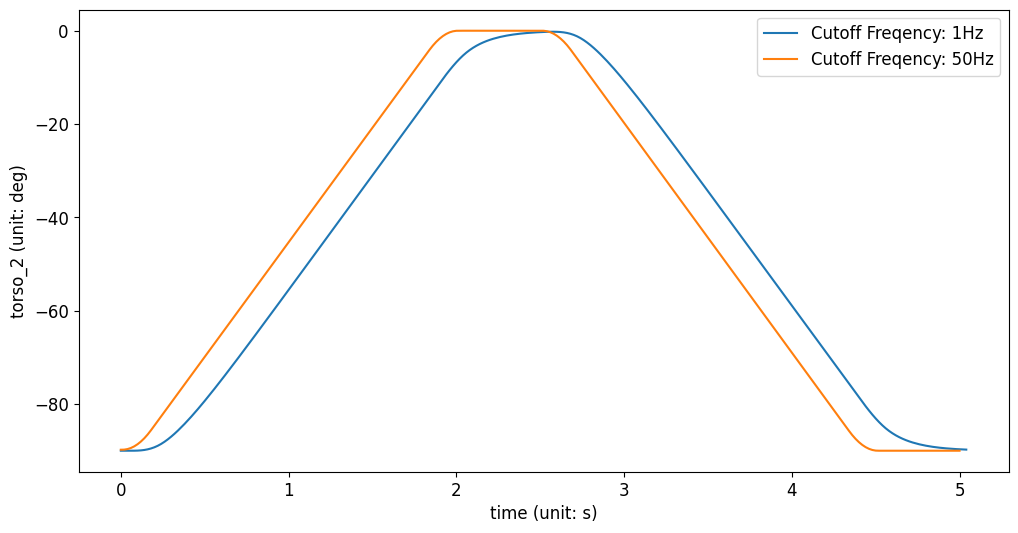

In [54]:
recorded_data = {
    1: np.vstack(ex4_cutoff_frequency(1)),
    50: np.vstack(ex4_cutoff_frequency(50)),
}
robot.stop_state_update()

plt.figure(figsize=(12, 6), facecolor='white', dpi=100)
plt.rcParams.update({'font.size': 12})

plt.plot(np.arange(0, recorded_data[1].shape[0]) * 0.02, np.rad2deg(recorded_data[1][:, 4]),
         np.arange(0, recorded_data[50].shape[0]) * 0.02, np.rad2deg(recorded_data[50][:, 4]))
plt.xlabel('time (unit: s)')
plt.ylabel('torso_2 (unit: deg)')
plt.legend(['Cutoff Freqency: 1Hz', 'Cutoff Freqency: 50Hz'])

# Minimum Time

In [50]:
class Recoder:
    """ContextManager to record target_position and position(encoder)"""

    def __init__(self, robot, record_freq=10):
        self.robot = robot
        self.record_freq = record_freq
        self.target_position = []
        self.position = []
        self.velocity = []
        self.timestamp = []

    # __enter__: with문 들어갈 때 실행
    def __enter__(self):
        self.target_position = []
        self.position = []
        self.velocity = []
        self.timestamp = []

        self.robot.stop_state_update()
        self.robot.start_state_update(self.cb, rate=self.record_freq)

    # __exit__: with문 나올 때 실행
    def __exit__(self, type, value, traceback):
        self.robot.stop_state_update()

    def cb(self, robot_state, control_manager_state):
        self.target_position.append(robot_state.target_position)
        self.position.append(robot_state.position)
        self.velocity.append(robot_state.velocity)

    def add_timestamp(self):
        self.timestamp.append(len(self.position))
        

def ex5_move_right_arm(position, velocity_limit=None, acceleration_limit=None, minimum_time=2.0):
    robot.set_parameter("joint_position_command.cutoff_frequency", "5.0")
    jpc_builder = (
        rby.JointPositionCommandBuilder()
        .set_minimum_time(minimum_time)
        .set_position(position)
    )
    if velocity_limit is not None:
        jpc_builder.set_velocity_limit(velocity_limit)
    if acceleration_limit is not None:
        jpc_builder.set_acceleration_limit(acceleration_limit)

    rc_builder = rby.RobotCommandBuilder().set_command(
        rby.ComponentBasedCommandBuilder().set_body_command(
            rby.BodyComponentBasedCommandBuilder()
            # Set Right Command with Joint Position Command
            .set_right_arm_command(jpc_builder)
        )
    )
    rc = robot.send_command(rc_builder).get()
    return rc.finish_code == rby.RobotCommandFeedback.FinishCode.Ok

Text(0.02, 0.5, 'right_arm_3 (unit: deg)')

<Figure size 1200x600 with 0 Axes>

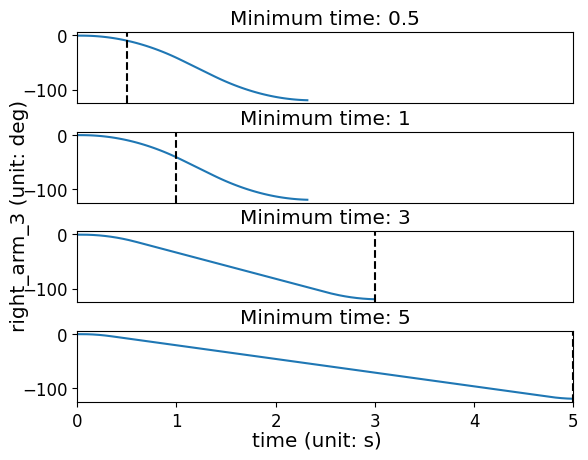

In [51]:
recorder = Recoder(robot, 50)
minimum_times = [0.5, 1, 3, 5]

data = {}
for minimum_time in minimum_times:
    ex5_move_right_arm([0.] * 7, minimum_time=1.)
    time.sleep(1.0)

    with recorder:
        ex5_move_right_arm(np.deg2rad([0.0, -5.0, 0.0, -120.0, 0.0, 70.0, 0.0]), np.deg2rad([90] * 7),
                           np.deg2rad([90] * 7), minimum_time)
    data[minimum_time] = (
        np.vstack(recorder.target_position),
        np.vstack(recorder.position),
        np.vstack(recorder.velocity)
    )
    

### Plot ###
plt.figure(figsize=(12, 6), facecolor='white', dpi=100)
plt.rcParams.update({'font.size': 12})

fig, ax = plt.subplots(4, 1)

for i, minimum_time in enumerate(minimum_times):
    ax[i].set_title(f'Minimum time: {minimum_time}')
    ax[i].plot(np.arange(0, data[minimum_time][0].shape[0]) * 0.02,
               np.rad2deg(data[minimum_time][0][:, model.right_arm_idx[3]]))
    ax[i].axvline(x=minimum_time, color='k', linestyle='--')
    ax[i].set_xlim([0, max(minimum_times)])
    if i != len(minimum_times) - 1:
        ax[i].get_xaxis().set_visible(False)

plt.subplots_adjust(hspace=0.4)
fig.supxlabel('time (unit: s)')
fig.supylabel('right_arm_3 (unit: deg)')

# Command Stream

In [ ]:
def ex6_7_move_right_arm_builder(position, velocity_limit=None, acceleration_limit=None, minimum_time=2.0):
    jpc_builder = (
        rby.JointPositionCommandBuilder()
        .set_command_header(rby.CommandHeaderBuilder().set_control_hold_time(10))
        .set_minimum_time(minimum_time)
        .set_position(position)
    )
    if velocity_limit is not None:
        jpc_builder.set_velocity_limit(velocity_limit)
    if acceleration_limit is not None:
        jpc_builder.set_acceleration_limit(acceleration_limit)

    rc_builder = rby.RobotCommandBuilder().set_command(
        rby.ComponentBasedCommandBuilder().set_body_command(
            rby.BodyComponentBasedCommandBuilder()
            # Set Right Command with Joint Position Command
            .set_right_arm_command(jpc_builder)
        )
    )
    return rc_builder